# 03 · M1 — Probabilidad de ignición y duración de llamas de gas en microgravedad

**Tareas:** DS-08 → DS-13 (M1 + M3) · **Datos:** `gas_flame_tests`, solo CFI-G (PSI-159) · **Código reutilizable:**
`src/flamesafe/models/m1.py` (con tests) · **Plan:** [MODELING_PLAN.md](../../docs/03_data_science/MODELING_PLAN.md)

Dos preguntas operativas, elegidas por utilidad para quien diseña la atmósfera de un hábitat:

1. **¿Se enciende?** Probabilidad de ignición dadas O₂, presión y la fuente de combustible.
2. **Si se enciende, ¿cuánto tiempo sigue ardiendo?** Probabilidad de que la llama siga viva a los *t* segundos.

> Los resultados son **candidatos** hasta la revisión PHY (PHY-03/04). PSI es microgravedad: nada de aquí es evidencia de gravedad
> parcial. Cualquier lectura para la Luna o Marte es interpolación en µg y se marca como tal.

## 0. Decisiones fijadas antes de ajustar

| Tema | Decisión | Por qué |
|---|---|---|
| Población | Solo CFI-G; normales e inversas **por separado** | Flame Design es 98.8 % "yes" (no enseña cuándo *no* hay llama). En inversas el O₂ sale del quemador y el ambiente es combustible |
| Exclusiones | `x_fuel = 0` (2 controles) y 21265H1 (cronología imposible, auditoría del PR #3) | Igual que RQ1 y el EDA del equipo; el EDA mostró que no cambian las tasas |
| `flash` | Fuera del objetivo binario y de la cohorte de supervivencia; **sensibilidad** como "yes"/"no" y como extinción inmediata | Decisión PHY 2026-11-14 |
| Duración | Autoextinción = **evento**; `flow_terminated` = **censura por la derecha** en `burn_time_s` | La llama seguía viva cuando se cortó el flujo: sabemos que duró *al menos* eso |
| Validación | **Dejar fuera un día completo** (11 días normales, 12 inversas) | Las pruebas de una jornada comparten hardware y calibración |
| Métricas | Ignición: log-loss (principal), Brier, AUC. Duración: índice C de Harrell | Probabilidades calibradas importan más que el ranking para un umbral de riesgo |
| Baselines | Trivial (tasa base / sin covariables) y físico (O₂ + presión; O₂ solo en duración) | Criterio G4: superar ambos con IC que no cruce cero |
| Incertidumbre | IC por **bootstrap de días completos**; Cox con errores agrupados por día | Pocas jornadas: los errores de prueba independiente subestiman la incertidumbre |
| Dominio | Una predicción de atmósfera se muestra solo si hay ≥ 5 pruebas cercanas (±0.05 O₂, ±25 % presión) de ≥ 2 días | Fuera de eso: "sin evidencia" |

In [1]:
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from lifelines import KaplanMeierFitter
from sklearn.ensemble import HistGradientBoostingClassifier

from flamesafe import config
from flamesafe.analysis import stats
from flamesafe.models import m1
from flamesafe.physics.atmospheres import REFERENCE_ATMOSPHERES

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9})
FUEL_COLORS = {"butane": "#2a78d6", "ethane": "#eb6834", "propane": "#1baf7a"}  # fixed order, first three slots
TERTILE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED = "#0b0b0b", "#8a8984"
N_BOOT = 300

con = duckdb.connect(str(config.data_dir() / "gold" / "flamesafe.duckdb"), read_only=True)
gas = con.sql("SELECT * FROM gas_flame_tests").df()
con.close()

ign = m1.ignition_cohort(gas)
surv = m1.survival_cohort(gas)
summary = pd.DataFrame({
    "ignition_n": ign.groupby("flame_type").size(),
    "ignited_yes": ign.groupby("flame_type").y.sum().astype(int),
    "survival_n": surv.groupby("flame_type").size(),
    "self_extinguished": surv.groupby("flame_type").event.sum(),
    "censored_flow_cut": surv.groupby("flame_type").event.apply(lambda e: int((e == 0).sum())),
    "days": ign.groupby("flame_type").test_day.nunique(),
})
summary

,ignition_n,ignited_yes,survival_n,self_extinguished,censored_flow_cut,days
flame_type,,,,,,
inverse,145,130,130,72,58,12
normal,177,132,132,102,30,11


## 1. Probabilidad de ignición

Candidatos, todos evaluados con las mismas particiones (un día fuera por vez):

- **trivial**: tasa de ignición del entrenamiento.
- **o2_p (baseline físico)**: logística con O₂ y log-presión, el mapa clásico de inflamabilidad.
- **linear**: la forma pre-registrada en RQ1 (O₂ + log-presión + log fracción de combustible + combustible).
- **phys**: variables termoquímicas derivadas (Tad calculada, Zst, log-presión). Primera versión de la idea de usar modelos
  físicos: si la física está bien resumida en Tad/Zst, este modelo debería competir con el de variables crudas.
- **spline (candidato final)**: logística con penalización L2, spline cúbico en log fracción de combustible (los tres regímenes de
  RQ1) y la fuerza de penalización elegida **dentro** de cada partición de entrenamiento (CV anidada).
- **hgb_mono**: gradient boosting poco profundo con O₂ monótono creciente, solo como comparador.

In [2]:
def glm_fp(formula):
    def fp(train, test):
        return smf.glm(formula, train, family=sm.families.Binomial()).fit().predict(test).to_numpy()
    return fp


def hgb_fp(train, test):
    cols = ["xo2", "log_p", "log_xfuel"]
    model = HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150, min_samples_leaf=10,
                                           monotonic_cst={"xo2": 1}, random_state=26)
    return model.fit(train[cols], train.y).predict_proba(test[cols])[:, 1]


IGNITION_CANDIDATES = {
    "trivial": lambda tr, te: np.full(len(te), tr.y.mean()),
    "o2_p": glm_fp("y ~ xo2 + log_p"),
    "linear": glm_fp("y ~ xo2 + log_p + log_xfuel + C(fuel)"),
    "phys": glm_fp("y ~ tad_k + zst + log_p"),
    "spline": m1.nested_ignition_fp(),
    "hgb_mono": hgb_fp,
}

oof_ign, rows = {}, []
for ft, d in ign.groupby("flame_type"):
    for name, fp in IGNITION_CANDIDATES.items():
        pred, skipped = m1.grouped_oof(d, fp)
        oof_ign[(ft, name)] = pred
        met = m1.binary_metrics(d.y, pred)
        if name == "trivial":
            met["auc"] = 0.5  # constant within each fold: pooled AUC across folds is an artifact, not skill
        rows.append({"flame_type": ft, "model": name, **met, "folds_skipped": skipped})
ign_cv = pd.DataFrame(rows).round(3)
ign_cv

,flame_type,model,log_loss,brier,auc,folds_skipped
0,inverse,trivial,0.347,0.095,0.500,0
1,inverse,o2_p,0.295,0.087,0.746,0
2,inverse,linear,0.319,0.081,0.772,0
3,inverse,phys,0.304,0.085,0.791,0
4,inverse,spline,0.302,0.093,0.803,0
5,inverse,hgb_mono,0.331,0.089,0.806,0
6,normal,trivial,0.609,0.205,0.500,0
7,normal,o2_p,0.628,0.206,0.438,0
8,normal,linear,0.726,0.210,0.599,0
9,normal,phys,0.555,0.182,0.684,0


**Diferencia de log-loss frente a los baselines**, con IC 95 % por bootstrap de días sobre las predicciones fuera de muestra
(valores negativos = el candidato es mejor). Este es el criterio G4.

In [3]:
def delta_logloss(df, a, b):
    return m1.binary_metrics(df.y, df[a])["log_loss"] - m1.binary_metrics(df.y, df[b])["log_loss"]


rows = []
for ft, d in ign.groupby("flame_type"):
    frame = d[["y", "test_day"]].assign(**{k: oof_ign[(ft, k)] for k in IGNITION_CANDIDATES})
    for cand in ["o2_p", "linear", "phys", "spline", "hgb_mono"]:
        for base in ["trivial", "o2_p"]:
            if cand == base:
                continue
            bs = stats.cluster_bootstrap(frame, lambda f, c=cand, b=base: delta_logloss(f, c, b), n_boot=1000)
            rows.append({"flame_type": ft, "candidate": cand, "vs": base, "delta_log_loss": bs["estimate"],
                         "ci_low": bs["ci_low"], "ci_high": bs["ci_high"], "beats": bs["ci_high"] < 0})
ign_delta = pd.DataFrame(rows).round(3)
ign_delta

,flame_type,candidate,vs,delta_log_loss,ci_low,ci_high,beats
0,inverse,o2_p,trivial,-0.052,-0.145,0.047,False
1,inverse,linear,trivial,-0.028,-0.155,0.100,False
2,inverse,linear,o2_p,0.024,-0.029,0.083,False
3,inverse,phys,trivial,-0.043,-0.154,0.086,False
4,inverse,phys,o2_p,0.009,-0.031,0.065,False
5,inverse,spline,trivial,-0.045,-0.136,0.066,False
6,inverse,spline,o2_p,0.007,-0.046,0.079,False
7,inverse,hgb_mono,trivial,-0.016,-0.177,0.156,False
8,inverse,hgb_mono,o2_p,0.036,-0.064,0.160,False
9,normal,o2_p,trivial,0.020,-0.037,0.102,False


### 1.1 Calibración del modelo final (fuera de muestra)

Si el modelo dice 80 %, ¿se encienden cerca del 80 % de esas pruebas? Quintiles de probabilidad predicha frente a la tasa observada
(con intervalo de Wilson). Con 145–177 pruebas, cada punto tiene unas 30.

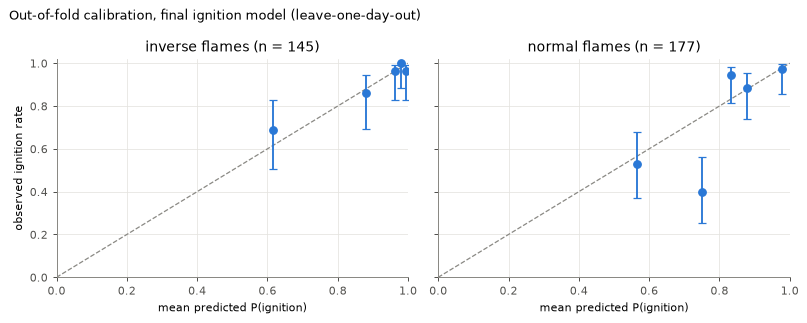

In [4]:
from statsmodels.stats.proportion import proportion_confint

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (ft, d) in zip(axes, ign.groupby("flame_type"), strict=False):
    p = oof_ign[(ft, "spline")]
    bins = pd.qcut(p.rank(method="first"), 5, labels=False)
    g = pd.DataFrame({"p": p, "y": d.y, "b": bins}).groupby("b").agg(p=("p", "mean"), k=("y", "sum"), n=("y", "size"))
    lo, hi = proportion_confint(g.k, g.n, method="wilson")
    obs = g.k / g.n
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    ax.errorbar(g.p, obs, yerr=[obs - lo, hi - obs], fmt="o", color="#2a78d6", ms=6, capsize=3, lw=1.5)
    ax.set(title=f"{ft} flames (n = {len(d)})", xlabel="mean predicted P(ignition)", xlim=(0, 1), ylim=(0, 1.02))
axes[0].set_ylabel("observed ignition rate")
fig.suptitle("Out-of-fold calibration, final ignition model (leave-one-day-out)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

### 1.2 Qué aprendió el modelo final

Curvas de P(ignición) contra O₂ para **llamas normales** a 1 atm, con la fracción de combustible del quemador en su valor típico
(0.3). Banda: IC 90 % por bootstrap de días (penalización fijada en la elegida con todos los datos). Las marcas abajo y arriba son
las pruebas reales (no / sí) de cada combustible.

Selected L2 strength C: {'inverse': 3.0, 'normal': 3.0}


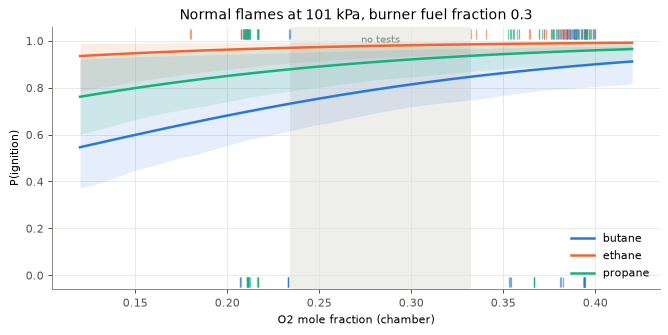

In [5]:
FINAL_C = {ft: m1.select_c(d) for ft, d in ign.groupby("flame_type")}
print("Selected L2 strength C:", FINAL_C)


def ignition_fit_predict(c):
    def fp(train, test):
        return m1.ignition_pipeline(c).fit(train, train.y).predict_proba(test)[:, 1]
    return fp


def shade_o2_gap(ax, d):
    # grey band where the normal-flame design has no tests (between the ~0.21 and ~0.35 O2 clusters)
    lo, hi = d.xo2[d.xo2 < 0.3].max(), d.xo2[d.xo2 > 0.3].min()
    ax.axvspan(lo, hi, color="#e4e3df", alpha=0.6, lw=0, zorder=0)
    ax.text((lo + hi) / 2, 0.94, "no tests", transform=ax.get_xaxis_transform(), ha="center", color=MUTED, fontsize=8)


normal_ign = ign[ign.flame_type == "normal"]
grid = pd.DataFrame([{"xo2": x, "log_p": np.log(101.33), "log_xfuel": np.log(0.3), "fuel": f}
                     for f in FUEL_COLORS for x in np.linspace(0.12, 0.42, 31)])
curve = m1.bootstrap_predict(normal_ign, ignition_fit_predict(FINAL_C["normal"]), grid, n_boot=N_BOOT)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for fuel, color in FUEL_COLORS.items():
    c = curve[curve.fuel == fuel]
    ax.fill_between(c.xo2, c.lo, c.hi, color=color, alpha=0.12, lw=0)
    ax.plot(c.xo2, c.pred, color=color, lw=2, label=fuel)
    obs = normal_ign[normal_ign.fuel == fuel]
    ax.plot(obs.xo2, np.where(obs.y == 1, 1.03, -0.03), "|", color=color, ms=8, alpha=0.6)
shade_o2_gap(ax, normal_ign)
ax.set(xlabel="O2 mole fraction (chamber)", ylabel="P(ignition)", ylim=(-0.06, 1.06),
       title="Normal flames at 101 kPa, burner fuel fraction 0.3")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### 1.3 Sensibilidad `flash` (llamas inversas)

Los 8 `flash` son de etano en llama inversa. Se reevalúa el modelo final contándolos como "yes" y como "no".

In [6]:
rows = []
for label in [None, "yes", "no"]:
    d = m1.ignition_cohort(gas, flash_as=label)
    d = d[d.flame_type == "inverse"]
    pred, _ = m1.grouped_oof(d, m1.nested_ignition_fp())
    base, _ = m1.grouped_oof(d, IGNITION_CANDIDATES["trivial"])
    rows.append({"flash_as": label or "excluded", "n": len(d), **m1.binary_metrics(d.y, pred),
                 "trivial_log_loss": m1.binary_metrics(d.y, base)["log_loss"]})
pd.DataFrame(rows).round(3)

,flash_as,n,log_loss,brier,auc,trivial_log_loss
0,excluded,145,0.302,0.093,0.803,0.347
1,yes,153,0.368,0.117,0.741,0.334
2,no,153,0.315,0.096,0.860,0.454


## 2. Duración de la llama (análisis de supervivencia)

Una llama encendida termina de dos formas: se **autoextingue** (evento) o **se corta el flujo** con la llama aún viva (censura).
Tratar los cortes como si fueran extinciones subestimaría la duración de las llamas más robustas, que son justo las peligrosas.

Primero, cómo se distribuyen los tiempos de corte: si son un temporizador fijo, la censura es administrativa (lo deseable); si los
decidía el operador mirando la llama, podría ser informativa (pregunta para PHY).

In [7]:
cut = surv[surv.event == 0]
print(cut.groupby("flame_type").duration_s.describe().round(1))
print("\nMost common flow-cut times (s):")
for ft, g in cut.groupby("flame_type"):
    print(f"  {ft}: {g.duration_s.round().value_counts().head(4).to_dict()}")
print("\nConditions by outcome (median):")
print(surv.groupby(["flame_type", "event"])[["xo2", "p_kpa", "x_fuel", "duration_s"]].median().round(3))

            count  mean   std   min   25%   50%    75%    max
flame_type                                                   
inverse      58.0  60.3  27.6  12.0  43.0  66.0   66.0  152.0
normal       30.0  91.8  76.1  13.0  34.2  61.5  127.0  276.0

Most common flow-cut times (s):
  inverse: {66.0: 26, 35.0: 2, 36.0: 2, 26.0: 2}
  normal: {61.0: 2, 127.0: 2, 43.0: 2, 29.0: 2}

Conditions by outcome (median):
                    xo2    p_kpa  x_fuel  duration_s
flame_type event                                    
inverse    0      0.500   82.583   0.199        66.0
           1      0.850  220.660   0.087         9.0
normal     0      0.383  101.330   0.300        61.5
           1      0.373  101.330   0.300        29.5


### 2.1 Kaplan–Meier por tercil de O₂

Curvas empíricas, sin modelo: proporción de llamas que siguen vivas a cada tiempo. Las líneas discontinuas son la predicción
promedio del modelo Weibull final para las mismas pruebas (chequeo de ajuste).

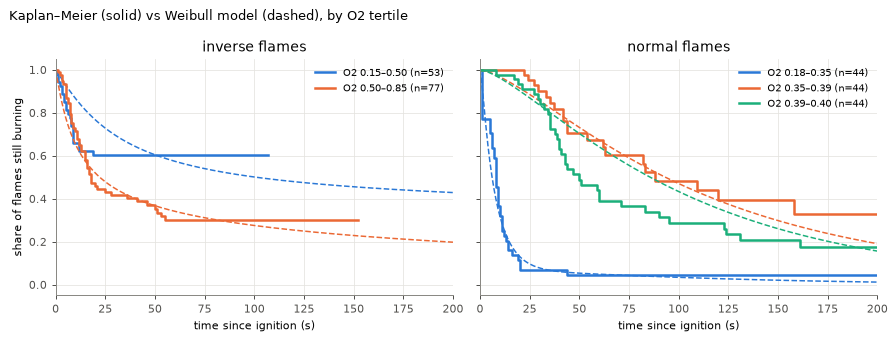

In [8]:
SURV_FORMULAS = {
    "o2": "xo2",
    "o2_p": "xo2 + log_p",
    "full": "xo2 + log_p + log_xfuel + log_flow + C(fuel)",
    "phys": "tad_k + zst + log_p + log_flow",
}
FINAL_SURV = SURV_FORMULAS["full"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
t_grid = np.linspace(0, 200, 201)
for ax, (ft, d) in zip(axes, surv.groupby("flame_type"), strict=False):
    model = m1.fit_weibull_aft(d, FINAL_SURV)
    terc = pd.qcut(d.xo2, 3, duplicates="drop")
    for color, (level, g) in zip(TERTILE_COLORS, d.groupby(terc, observed=True), strict=False):
        kmf = KaplanMeierFitter().fit(g.duration_s, g.event)
        kmf.plot_survival_function(ax=ax, ci_show=False, color=color, lw=2,
                                   label=f"O2 {level.left:.2f}–{level.right:.2f} (n={len(g)})")
        pred = model.predict_survival_function(g, times=t_grid).mean(axis=1)
        ax.plot(t_grid, pred, color=color, lw=1.2, ls="--")
    ax.set(title=f"{ft} flames", xlabel="time since ignition (s)", xlim=(0, 200))
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("share of flames still burning")
fig.suptitle("Kaplan–Meier (solid) vs Weibull model (dashed), by O2 tertile", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

**Lectura:** en llamas normales el modelo sigue bien las curvas empíricas. En los terciles de O₂ bajo (ambos tipos de llama) las
curvas de Kaplan–Meier se **aplanan**: una fracción de llamas no se apaga sola antes del corte. Un Weibull no puede representar
esa meseta (en inversas con O₂ bajo predice ~0.45 a 100 s frente a ~0.6 observado). Si PHY confirma que son llamas estables,
el siguiente paso natural es un modelo de **fracción curada** (mezcla de llamas que se apagan y llamas estables).

### 2.2 Validación: ¿el modelo ordena bien qué llamas duran más?

Índice C fuera de muestra (un día fuera por vez). 0.5 = azar (lo que logra un modelo sin covariables). IC 95 % y diferencia frente
al baseline físico (solo O₂) por bootstrap de días.

In [9]:
def weibull_fp(formula):
    def fp(train, test):
        return m1.fit_weibull_aft(train, formula).predict_median(test).to_numpy()
    return fp


oof_surv, rows = {}, []
for ft, d in surv.groupby("flame_type"):
    for name, formula in SURV_FORMULAS.items():
        pred, skipped = m1.grouped_oof(d, weibull_fp(formula))
        oof_surv[(ft, name)] = pred
    frame = d[["duration_s", "event", "test_day"]].assign(**{k: oof_surv[(ft, k)] for k in SURV_FORMULAS})
    for name in SURV_FORMULAS:
        c = stats.cluster_bootstrap(frame, lambda f, n=name: m1.concordance(f.duration_s, f[n], f.event), n_boot=1000)
        dc = stats.cluster_bootstrap(
            frame, lambda f, n=name: m1.concordance(f.duration_s, f[n], f.event) - m1.concordance(f.duration_s, f.o2, f.event),
            n_boot=1000) if name != "o2" else {"estimate": 0.0, "ci_low": np.nan, "ci_high": np.nan}
        rows.append({"flame_type": ft, "model": name, "c_index": c["estimate"], "ci_low": c["ci_low"], "ci_high": c["ci_high"],
                     "delta_vs_o2": dc["estimate"], "delta_ci_low": dc["ci_low"], "delta_ci_high": dc["ci_high"]})
surv_cv = pd.DataFrame(rows).round(3)
surv_cv

,flame_type,model,c_index,ci_low,ci_high,delta_vs_o2,delta_ci_low,delta_ci_high
0,inverse,o2,0.407,0.325,0.521,0.000,NaN,NaN
1,inverse,o2_p,0.736,0.603,0.859,0.328,0.173,0.446
2,inverse,full,0.821,0.703,0.902,0.414,0.263,0.510
3,inverse,phys,0.750,0.604,0.876,0.343,0.174,0.477
4,normal,o2,0.676,0.566,0.724,0.000,NaN,NaN
5,normal,o2_p,0.712,0.600,0.763,0.037,-0.001,0.073
6,normal,full,0.809,0.754,0.844,0.133,0.065,0.227
7,normal,phys,0.813,0.757,0.859,0.138,0.068,0.236


### 2.3 Efectos: cuánto cambia la duración

Dos lecturas complementarias del mismo modelo completo:

- **Razón de tiempos (Weibull AFT):** por cuánto se multiplica la duración típica. > 1 = la llama dura más. IC por bootstrap de días.
- **Razón de riesgos (Cox, errores agrupados por día):** por cuánto se multiplica el riesgo instantáneo de autoextinción. < 1 =
  la llama dura más. Es la lectura inferencial principal.

Escalas: +0.05 de fracción de O₂; presión, fracción de combustible y caudal **duplicados**.

In [10]:
SCALE = {"xo2": 0.05, "log_p": np.log(2), "log_xfuel": np.log(2), "log_flow": np.log(2)}
effects = []
for ft, d in surv.groupby("flame_type"):
    tr = m1.time_ratios_bootstrap(d, FINAL_SURV, SCALE, n_boot=N_BOOT)
    hr = m1.hazard_ratios(m1.fit_cox(d, FINAL_SURV), SCALE).set_index("term")
    tr = tr.set_index("term")[["per", "time_ratio", "boot_ci_low", "boot_ci_high"]]
    tr = tr.join(hr[["hazard_ratio", "ci_low", "ci_high", "p_value"]].add_prefix("cox_"))
    effects.append(tr.assign(flame_type=ft).reset_index())
effects = pd.concat(effects, ignore_index=True).round(3)
effects

,term,per,time_ratio,boot_ci_low,boot_ci_high,cox_hazard_ratio,cox_ci_low,cox_ci_high,cox_p_value,flame_type
0,xo2,0.050,0.872,0.814,0.988,1.123,1.024,1.231,0.014,inverse
1,log_p,0.693,1.210,0.694,1.508,0.844,0.575,1.240,0.388,inverse
2,log_xfuel,0.693,16.864,6.595,46.782,0.049,0.018,0.135,0.000,inverse
3,log_flow,0.693,1.381,0.842,2.358,0.692,0.457,1.046,0.081,inverse
4,C(fuel)[T.ethane],1.000,0.785,0.236,275864.812,1.118,0.484,2.587,0.794,inverse
5,C(fuel)[T.propane],1.000,0.567,0.173,22.282,1.193,0.505,2.817,0.688,inverse
6,xo2,0.050,2.286,1.903,2.549,0.191,0.128,0.286,0.000,normal
7,log_p,0.693,0.736,0.570,1.077,2.227,1.512,3.280,0.000,normal
8,log_xfuel,0.693,1.276,0.854,1.792,0.723,0.478,1.095,0.126,normal
9,log_flow,0.693,0.653,0.286,0.959,2.176,0.844,5.611,0.108,normal


### 2.4 Sensibilidad `flash` en duración

Se agregan los 8 `flash` de llama inversa como autoextinciones inmediatas (1 s) y se repite el efecto del O₂.

In [11]:
rows = []
for include in [False, True]:
    d = m1.survival_cohort(gas, include_flash=include)
    d = d[d.flame_type == "inverse"]
    tr = m1.time_ratios(m1.fit_weibull_aft(d, FINAL_SURV), SCALE).set_index("term").loc["xo2"]
    hr = m1.hazard_ratios(m1.fit_cox(d, FINAL_SURV), SCALE).set_index("term").loc["xo2"]
    rows.append({"flash_included": include, "n": len(d), "events": int(d.event.sum()),
                 "time_ratio_xo2": tr.time_ratio, "cox_hr_xo2": hr.hazard_ratio,
                 "cox_ci": f"{hr.ci_low:.2f}–{hr.ci_high:.2f}"})
pd.DataFrame(rows).round(3)

,flash_included,n,events,time_ratio_xo2,cox_hr_xo2,cox_ci
0,False,130,72,0.872,1.123,1.02–1.23
1,True,138,80,0.954,1.019,0.91–1.14


## 3. Lectura para atmósferas de referencia (solo llamas normales)

En llama normal la cámara es la atmósfera, así que es la única geometría que se proyecta a un hábitat. Para cada atmósfera se
reporta primero **si hay evidencia cerca**; solo entonces la predicción del modelo con IC 90 %. Fuente de combustible fijada en sus
valores típicos de CFI-G: fracción 0.3 y caudal mediano de cada combustible.

In [12]:
normal_surv = surv[surv.flame_type == "normal"]
flow_med = normal_surv.groupby("fuel").m_fuel_mg_s.median()
ATM_KEYS = ["iss_cabin", "exploration_8p2_34", "lunar_base_upper", "spacesuit"]

scen = pd.DataFrame([{"atmosphere": REFERENCE_ATMOSPHERES[k].name, "key": k,
                      "xo2": REFERENCE_ATMOSPHERES[k].o2_mole_fraction,
                      "p_kpa": REFERENCE_ATMOSPHERES[k].total_pressure_kpa, "fuel": f}
                     for k in ATM_KEYS for f in FUEL_COLORS])
scen = scen.assign(log_p=np.log(scen.p_kpa), log_xfuel=np.log(0.3), x_fuel=0.3,
                   log_flow=np.log(scen.fuel.map(flow_med)))

dom = pd.DataFrame([{"key": k, **m1.domain_status(normal_ign, REFERENCE_ATMOSPHERES[k].o2_mole_fraction,
                                                   REFERENCE_ATMOSPHERES[k].total_pressure_kpa)} for k in ATM_KEYS])
inside = scen[scen.key.isin(dom.loc[dom.in_domain, "key"])].reset_index(drop=True)

p_ign = m1.bootstrap_predict(normal_ign, ignition_fit_predict(FINAL_C["normal"]), inside, n_boot=N_BOOT)


def median_fp(train, test):
    return m1.fit_weibull_aft(train, FINAL_SURV).predict_median(test).to_numpy()


def s60_fp(train, test):
    return m1.fit_weibull_aft(train, FINAL_SURV).predict_survival_function(test, times=[60.0]).to_numpy().ravel()


med = m1.bootstrap_predict(normal_surv, median_fp, inside, n_boot=N_BOOT)  # same seed -> same resamples
s60 = m1.bootstrap_predict(normal_surv, s60_fp, inside, n_boot=N_BOOT)

table = inside[["atmosphere", "fuel"]].assign(
    p_ignition=p_ign.pred.round(2), p_ignition_90ci=[f"{a:.2f}–{b:.2f}" for a, b in zip(p_ign.lo, p_ign.hi, strict=False)],
    median_burn_s=med.pred.round(0), median_burn_90ci=[f"{a:.0f}–{b:.0f}" for a, b in zip(med.lo, med.hi, strict=False)],
    p_still_burning_60s=s60.pred.round(2), p60_90ci=[f"{a:.2f}–{b:.2f}" for a, b in zip(s60.lo, s60.hi, strict=False)])
print(dom.assign(atmosphere=dom.key.map(lambda k: REFERENCE_ATMOSPHERES[k].name)).to_string(index=False))
table

               key  n_nearby  days_nearby  in_domain                       atmosphere
         iss_cabin        35            6       True                        ISS cabin
exploration_8p2_34        19            3       True Exploration atm 8.2 psi / 34% O2
  lunar_base_upper         0            0      False     Lunar base (challenge bound)
         spacesuit         0            0      False            Spacesuit (EMU-class)


,atmosphere,fuel,p_ignition,p_ignition_90ci,median_burn_s,median_burn_90ci,p_still_burning_60s,p60_90ci
0,ISS cabin,butane,0.70,0.58–0.94,5.0,3–8,0.00,0.00–0.00
1,ISS cabin,ethane,0.97,0.89–0.99,8.0,5–15,0.00,0.00–0.00
2,ISS cabin,propane,0.86,0.76–0.96,5.0,3–13,0.00,0.00–0.00
3,Exploration atm 8.2 psi / 34% O2,butane,0.84,0.76–0.95,52.0,37–69,0.42,0.22–0.57
4,Exploration atm 8.2 psi / 34% O2,ethane,0.98,0.93–1.00,90.0,53–116,0.68,0.43–0.81
5,Exploration atm 8.2 psi / 34% O2,propane,0.93,0.81–0.98,58.0,27–93,0.49,0.10–0.74


**Contraste empírico (sin modelo).** Pruebas reales de llama normal cercanas a cada atmósfera dentro del dominio: tasa de ignición
observada y mediana de duración de Kaplan–Meier. Si el modelo y los datos cercanos no se parecen, manda el dato.

In [13]:
rows = []
for key in dom.loc[dom.in_domain, "key"]:
    a = REFERENCE_ATMOSPHERES[key]
    ni = m1.nearby_tests(normal_ign, a.o2_mole_fraction, a.total_pressure_kpa)
    ns = m1.nearby_tests(normal_surv, a.o2_mole_fraction, a.total_pressure_kpa)
    km = KaplanMeierFitter().fit(ns.duration_s, ns.event) if len(ns) else None
    rows.append({"atmosphere": a.name, "nearby_ignition_tests": len(ni), "days": ni.test_day.nunique(),
                 "observed_ignition_rate": round(ni.y.mean(), 2), "nearby_burning_flames": len(ns),
                 "censored": int((ns.event == 0).sum()),
                 "km_median_burn_s": km.median_survival_time_ if km is not None else np.nan})
pd.DataFrame(rows)

,atmosphere,nearby_ignition_tests,days,observed_ignition_rate,nearby_burning_flames,censored,km_median_burn_s
0,ISS cabin,35,6,0.66,23,0,9.0
1,Exploration atm 8.2 psi / 34% O2,19,3,0.84,16,4,88.0


### 3.1 Duración predicha frente a O₂ (vista para el dashboard)

Mediana de duración predicha por el modelo para llamas normales a 101 kPa y a 56.5 kPa (presión de la atmósfera de exploración),
promediando combustibles con su caudal típico. Puntos: pruebas reales (rellenos = autoextinción; huecos = corte de flujo, la llama
duró *al menos* eso). Banda: IC 90 % por bootstrap de días.

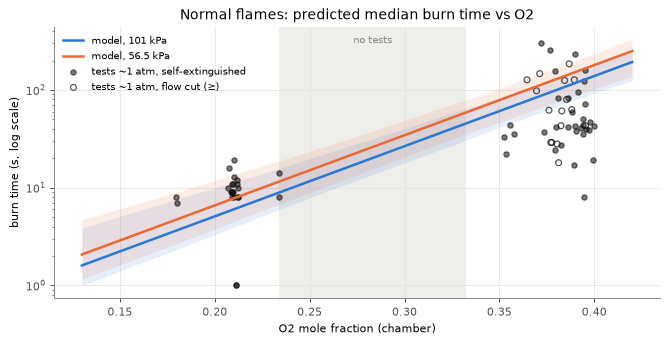

In [14]:
xs = np.linspace(0.13, 0.42, 30)
pressures = {"101 kPa": 101.33, "56.5 kPa": REFERENCE_ATMOSPHERES["exploration_8p2_34"].total_pressure_kpa}
fig, ax = plt.subplots(figsize=(7.5, 3.9))
for color, (label, p) in zip(["#2a78d6", "#eb6834"], pressures.items(), strict=False):
    g = pd.DataFrame([{"xo2": x, "log_p": np.log(p), "log_xfuel": np.log(0.3), "fuel": f,
                       "log_flow": np.log(flow_med[f])} for x in xs for f in FUEL_COLORS])

    def fp(train, test):
        return m1.fit_weibull_aft(train, FINAL_SURV).predict_median(test).to_numpy()

    out = m1.bootstrap_predict(normal_surv, fp, g, n_boot=150).groupby("xo2")[["pred", "lo", "hi"]].mean()
    ax.fill_between(out.index, out.lo, out.hi, color=color, alpha=0.12, lw=0)
    ax.plot(out.index, out.pred, color=color, lw=2, label=f"model, {label}")
near_p = normal_surv[normal_surv.p_kpa.between(80, 125)]
ax.scatter(near_p.xo2[near_p.event == 1], near_p.duration_s[near_p.event == 1], s=18, color=INK, alpha=0.55,
           label="tests ~1 atm, self-extinguished")
ax.scatter(near_p.xo2[near_p.event == 0], near_p.duration_s[near_p.event == 0], s=22, facecolors="none",
           edgecolors=INK, alpha=0.7, label="tests ~1 atm, flow cut (≥)")
shade_o2_gap(ax, normal_surv)
ax.set(yscale="log", xlabel="O2 mole fraction (chamber)", ylabel="burn time (s, log scale)",
       title="Normal flames: predicted median burn time vs O2")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 4. Conclusiones (v1, candidatos a finding hasta PHY-03/04)

### Duración de la llama: el resultado fuerte

- **Llamas normales:** el modelo completo ordena bien qué llamas duran más (índice C fuera de muestra 0.81, IC 0.75–0.84) y
  supera al baseline de solo O₂ por +0.13 (IC 0.07–0.23). Con variables termoquímicas derivadas (Tad, Zst) rinde igual (0.81).
- **El O₂ es el factor dominante.** Cada +0.05 de fracción de O₂ multiplica por ~2.3 la duración típica (IC 1.9–2.5) y reduce
  ~81 % el riesgo instantáneo de autoextinción (Cox con errores por día: HR 0.19, IC 0.13–0.29).
- **Más presión acorta la llama** (duplicar la presión: HR 2.2, IC 1.5–3.3), y el etano dura más que butano y propano.
  ⚠️ Una explicación plausible es la mayor pérdida por radiación a alta presión, pero eso lo tiene que confirmar PHY.
- **Llamas inversas:** C = 0.82 (IC 0.70–0.90). Lo que manda es la fracción de combustible del **ambiente** (duplicarla: HR 0.05).
  El efecto del O₂ del quemador (HR 1.12) **no es robusto** a incluir los `flash`.

### Probabilidad de ignición: útil pero modesta

- **Llamas normales:** el modelo final (logística penalizada con spline en la fracción de combustible) cumple el criterio G4:
  log-loss 0.485 frente a 0.609 del trivial (Δ −0.12, IC −0.19 a −0.06) y frente al baseline O₂ + presión (Δ −0.14). AUC 0.81.
- Pero lo que aporta la señal es **la fuente de combustible** (fracción y tipo), no la atmósfera: O₂ + presión solos no superan al
  trivial. La curva de O₂ va en la dirección esperada con bandas anchas, y un quintil está mal calibrado (predice ~0.75, observa ~0.40).
- **Llamas inversas:** ningún candidato supera a la tasa base con IC (90 % de igniciones, solo 15 "no"). El dashboard debe mostrar la
  tasa empírica, no una curva. Contar los `flash` como "no" cambia bastante el resultado: **esa decisión sí importa en inversas**.

### Lectura para hábitats (solo llamas normales, en microgravedad)

| Atmósfera | Evidencia cercana | Ignición observada / modelo | Duración mediana observada (KM) | Modelo: duración mediana / P(sigue a 60 s) |
|---|---|---|---|---|
| Cabina ISS (21 %, 101 kPa) | 35 pruebas, 6 días | 0.66 / 0.70–0.97 según combustible | 9 s (ninguna de 23 llegó al corte) | 5–8 s / ≈ 0 |
| Exploración (34 %, 56.5 kPa) | 19 pruebas, 3 días (borde del dominio) | 0.84 / 0.84–0.98 | 88 s (4 de 16 llegaron al corte) | 52–90 s / 0.42–0.68 |
| Base lunar (30 %, 70 kPa) | **0 pruebas**: cae en el hueco de diseño de O₂ (0.24–0.33) | — | — | sin evidencia |
| Traje (100 %, 30 kPa) | 0 pruebas | — | — | sin evidencia |

Cerca de la ISS el modelo de ignición **sobreestima** la tasa observada (0.66): para ignición, el dashboard debe mostrar primero el
dato empírico. En duración, modelo y datos coinciden.

**Candidato a finding principal:** en la atmósfera de exploración una llama ya encendida dura **unas 10 veces más** que en la
cabina de la ISS, y esto lo dicen tanto los datos cercanos como el modelo. Bajar la presión **no compensa** subir el O₂ en cuanto a
duración: en este modelo, menos presión también alarga la llama. Hay que leerlo siempre como microgravedad y llamas de chorro de gas.

### Límites y siguientes pasos

- **Censura:** en inversas 26 de 58 cortes ocurren justo a los 66 s (parece temporizador). En normales los cortes van de 13 a 276 s:
  si el operador cortaba mirando la llama, la censura podría ser informativa. **Pregunta para PHY.**
- **Mesetas:** en O₂ bajo una fracción de llamas no se apaga sola. Un modelo de fracción curada lo representaría mejor que Weibull.
- **Hueco de diseño:** no hay pruebas normales entre 0.24 y 0.33 de O₂; lo que el modelo dibuja ahí es interpolación.
- **Física reducida (idea del equipo):** las variables derivadas Tad/Zst ya igualan a las crudas en duración. El siguiente
  experimento es agregar un indicador de margen de extinción calculado con Cantera y medir si mejora el índice C fuera de muestra.
- Los IC por bootstrap de los coeficientes de combustible en inversas son inestables (algunas réplicas sin un combustible): no
  interpretarlos; el combustible no es significativo en el Cox de inversas.
- **Pendiente PHY:** firmar signos (O₂, presión, combustible), el tratamiento de la censura y la decisión `flash` en inversas.